In [1]:
import pandas as pd
import polars as pl
import duckdb
import time
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd

df = pd.read_csv("../W5D3/indian_business_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (50, 10)


,business_id,business_name,owner_name,state,city,age,email,phone,annual_revenue,gstin
0,B001,Sri Traders,Ravi Kumar,Andhra Pradesh,Tirupati,35,owner1@example.com,9000000001,500000,37ABCDE0001F1Z5
1,B002,ABC Stores,Anita Rao,Telangana,Hyderabad,42,owner2@example.com,9000000002,750000,37ABCDE0002F1Z5
2,B003,Lakshmi Textiles,Lakshmi Devi,Karnataka,Bengaluru,29,owner3@example.com,9000000003,420000,37ABCDE0003F1Z5
3,B004,Green Mart,Suresh Reddy,Tamil Nadu,Chennai,51,owner4@example.com,9000000004,900000,37ABCDE0004F1Z5
4,B005,Ravi Enterprises,Priya Sharma,Maharashtra,Pune,38,NaN,9000000005,650000,37ABCDE0005F1Z5


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   business_id     50 non-null     str  
 1   business_name   50 non-null     str  
 2   owner_name      50 non-null     str  
 3   state           50 non-null     str  
 4   city            50 non-null     str  
 5   age             50 non-null     int64
 6   email           49 non-null     str  
 7   phone           50 non-null     int64
 8   annual_revenue  50 non-null     int64
 9   gstin           50 non-null     str  
dtypes: int64(3), str(7)
memory usage: 4.0 KB

Missing Values:
business_id       0
business_name     0
owner_name        0
state             0
city              0
age               0
email             1
phone             0
annual_revenue    0
gstin             0
dtype: int64

Statistical Summary:


,business_id,business_name,owner_name,state,city,age,email,phone,annual_revenue,gstin
count,50,50,50,50,50,50.000000,49,5.000000e+01,50.000000,50
unique,49,10,10,5,5,NaN,49,NaN,NaN,50
top,B001,Sri Traders,Ravi Kumar,Andhra Pradesh,Tirupati,NaN,owner1@example.com,NaN,NaN,37ABCDE0001F1Z5
freq,2,5,5,10,10,NaN,1,NaN,NaN,1
mean,NaN,NaN,NaN,NaN,NaN,40.820000,NaN,9.000000e+09,629000.000000,NaN
std,NaN,NaN,NaN,NaN,NaN,17.305998,NaN,1.457738e+01,162722.375316,NaN
min,NaN,NaN,NaN,NaN,NaN,27.000000,NaN,9.000000e+09,380000.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,33.000000,NaN,9.000000e+09,500000.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,39.000000,NaN,9.000000e+09,625000.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,44.000000,NaN,9.000000e+09,750000.000000,NaN


In [6]:
print("Total Businesses:", len(df))

print("\nBusinesses by State:")
print(df["state"].value_counts())

print("\nAverage Annual Revenue:")
print(df["annual_revenue"].mean())

print("\nTotal Annual Revenue:")
print(df["annual_revenue"].sum())

Total Businesses: 50

Businesses by State:
state
Andhra Pradesh    10
Telangana         10
Karnataka         10
Tamil Nadu        10
Maharashtra       10
Name: count, dtype: int64

Average Annual Revenue:
629000.0

Total Annual Revenue:
31450000


In [7]:
import duckdb
import time

print("DuckDB version:", duckdb.__version__)

DuckDB version: 1.5.6


In [8]:
con = duckdb.connect(database=":memory:")

con.execute("""
    CREATE TABLE businesses AS
    SELECT * FROM read_csv_auto('../W5D3/indian_business_dataset.csv')
""")

print("Dataset loaded into DuckDB successfully!")

Dataset loaded into DuckDB successfully!


In [9]:
result1 = con.execute("""
    SELECT COUNT(*) AS total_businesses
    FROM businesses
""").df()

display(result1)

,total_businesses
0,50


In [10]:
result2 = con.execute("""
    SELECT SUM(annual_revenue) AS total_revenue
    FROM businesses
""").df()

display(result2)

,total_revenue
0,31450000.0


In [11]:
result3 = con.execute("""
    SELECT AVG(annual_revenue) AS average_revenue
    FROM businesses
""").df()

display(result3)

,average_revenue
0,629000.0


In [12]:
result4 = con.execute("""
    SELECT state,
           SUM(annual_revenue) AS total_revenue
    FROM businesses
    GROUP BY state
    ORDER BY total_revenue DESC
""").df()

display(result4)

,state,total_revenue
0,Tamil Nadu,8050000.0
1,Andhra Pradesh,6600000.0
2,Telangana,6550000.0
3,Maharashtra,6250000.0
4,Karnataka,4000000.0


In [13]:
result5 = con.execute("""
    SELECT business_name, state, annual_revenue
    FROM businesses
    ORDER BY annual_revenue DESC
    LIMIT 5
""").df()

display(result5)

,business_name,state,annual_revenue
0,Green Mart,Tamil Nadu,900000
1,Green Mart,Tamil Nadu,900000
2,Green Mart,Tamil Nadu,900000
3,Green Mart,Tamil Nadu,900000
4,Green Mart,Tamil Nadu,900000


In [14]:
import polars as pl
import time

print("Polars version:", pl.__version__)

Polars version: 2.2.0


In [15]:
pl_df = pl.read_csv("../W5D3/indian_business_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", pl_df.shape)

display(pl_df.head())

Dataset loaded successfully!
Shape: (50, 10)


business_id,business_name,owner_name,state,city,age,email,phone,annual_revenue,gstin
str,str,str,str,str,i64,str,i64,i64,str
"""B001""","""Sri Traders""","""Ravi Kumar""","""Andhra Pradesh""","""Tirupati""",35,"""owner1@example.com""",9000000001,500000,"""37ABCDE0001F1Z5"""
"""B002""","""ABC Stores""","""Anita Rao""","""Telangana""","""Hyderabad""",42,"""owner2@example.com""",9000000002,750000,"""37ABCDE0002F1Z5"""
"""B003""","""Lakshmi Textiles""","""Lakshmi Devi""","""Karnataka""","""Bengaluru""",29,"""owner3@example.com""",9000000003,420000,"""37ABCDE0003F1Z5"""
"""B004""","""Green Mart""","""Suresh Reddy""","""Tamil Nadu""","""Chennai""",51,"""owner4@example.com""",9000000004,900000,"""37ABCDE0004F1Z5"""
"""B005""","""Ravi Enterprises""","""Priya Sharma""","""Maharashtra""","""Pune""",38,null,9000000005,650000,"""37ABCDE0005F1Z5"""


In [16]:
pl_df.select(
    pl.len().alias("total_businesses")
)

total_businesses
u32
50


In [17]:
pl_df.select(
    pl.col("annual_revenue").sum().alias("total_revenue")
)

total_revenue
i64
31450000


In [18]:
pl_df.select(
    pl.col("annual_revenue").mean().alias("average_revenue")
)

average_revenue
f64
629000.0


In [19]:
pl_df.group_by("state").agg(
    pl.col("annual_revenue").sum().alias("total_revenue")
).sort("total_revenue", descending=True)

state,total_revenue
str,i64
"""Tamil Nadu""",8050000
"""Andhra Pradesh""",6600000
"""Telangana""",6550000
"""Maharashtra""",6250000
"""Karnataka""",4000000


In [20]:
pl_df.sort(
    "annual_revenue", descending=True
).select(
    ["business_name", "state", "annual_revenue"]
).head(5)

business_name,state,annual_revenue
str,str,i64
"""Green Mart""","""Tamil Nadu""",900000
"""Green Mart""","""Tamil Nadu""",900000
"""Green Mart""","""Tamil Nadu""",900000
"""Green Mart""","""Tamil Nadu""",900000
"""Green Mart""","""Tamil Nadu""",900000


In [21]:
import pandas as pd
import polars as pl
import duckdb
import time

csv_path = "../W5D1/indian_retail_sales.csv"

# Pandas
pandas_df = pd.read_csv(csv_path)

# Polars
polars_df = pl.read_csv(csv_path)

# DuckDB
con_bench = duckdb.connect(database=":memory:")

print("All datasets loaded successfully!")

print("Pandas shape:", pandas_df.shape)
print("Polars shape:", polars_df.shape)

All datasets loaded successfully!
Pandas shape: (100000, 25)
Polars shape: (100000, 25)


In [22]:
start = time.perf_counter()

pandas_result = (
    pandas_df.groupby("Region")
    .agg(
        total_sales=("Sales", "sum"),
        average_profit=("Profit", "mean")
    )
    .reset_index()
)

pandas_time = time.perf_counter() - start

display(pandas_result)
print("Pandas execution time:", pandas_time)

,Region,total_sales,average_profit
0,East,6.353223e+08,3788.161416
1,North,6.244511e+08,3717.581160
2,South,6.290598e+08,3764.156298
3,West,6.196078e+08,3751.190288


Pandas execution time: 0.018890699953772128


In [23]:
start = time.perf_counter()

polars_result = (
    polars_df.group_by("Region")
    .agg([
        pl.col("Sales").sum().alias("total_sales"),
        pl.col("Profit").mean().alias("average_profit")
    ])
)

polars_time = time.perf_counter() - start

display(polars_result)
print("Polars execution time:", polars_time)

Region,total_sales,average_profit
str,f64,f64
"""North""",6.2445e8,3717.58116
"""West""",6.1961e8,3751.190288
"""South""",6.2906e8,3764.156298
"""East""",6.3532e8,3788.161416


Polars execution time: 0.0028738999972119927


In [24]:
start = time.perf_counter()

duckdb_result = con_bench.execute("""
    SELECT
        Region,
        SUM(Sales) AS total_sales,
        AVG(Profit) AS average_profit
    FROM read_csv_auto('../W5D1/indian_retail_sales.csv')
    GROUP BY Region
    ORDER BY Region
""").df()

duckdb_time = time.perf_counter() - start

display(duckdb_result)
print("DuckDB execution time:", duckdb_time)

,Region,total_sales,average_profit
0,East,6.353223e+08,3788.161416
1,North,6.244511e+08,3717.581160
2,South,6.290598e+08,3764.156298
3,West,6.196078e+08,3751.190288


DuckDB execution time: 0.14890999998897314


In [25]:
benchmark = pd.DataFrame({
    "Technology": ["Pandas", "DuckDB", "Polars"],
    "Execution Time (seconds)": [
        pandas_time,
        duckdb_time,
        polars_time
    ]
})

display(benchmark.sort_values("Execution Time (seconds)"))

,Technology,Execution Time (seconds)
2,Polars,0.002874
0,Pandas,0.018891
1,DuckDB,0.148910


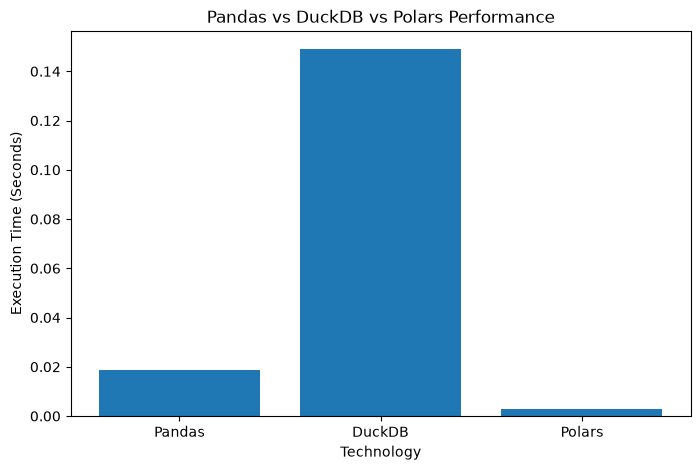

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    benchmark["Technology"],
    benchmark["Execution Time (seconds)"]
)

plt.title("Pandas vs DuckDB vs Polars Performance")
plt.xlabel("Technology")
plt.ylabel("Execution Time (Seconds)")

plt.show()